# Chapter 13 — Deploying scikit-learn Models in Production

**Reference:** *scikit-learn Cookbook, Third Edition* — John Sukup

This notebook demonstrates model persistence, inference timing, input monitoring, metadata, and model lifecycle practices.

## 1. Theory
Production use requires reliable inference, versioning, monitoring, and a controlled update process. A `Pipeline` packages preprocessing and the estimator so prediction inputs receive the same transformations as training inputs. **Security:** only load joblib/pickle artifacts from trusted sources; deserialization can execute code, and model compatibility across library versions is not guaranteed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RANDOM_STATE = 42

import json, time, platform
from pathlib import Path
from joblib import dump, load
import sklearn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
X,y=make_classification(n_samples=1200,n_features=20,n_informative=10,n_redundant=4,random_state=RANDOM_STATE)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.25,stratify=y,random_state=RANDOM_STATE)
model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000,random_state=RANDOM_STATE)).fit(X_train,y_train)
print("Python:",platform.python_version(),"| scikit-learn:",sklearn.__version__)
print("Held-out accuracy:",round(accuracy_score(y_test,model.predict(X_test)),3))


Python: 3.13.5 | scikit-learn: 1.8.0
Held-out accuracy: 0.82


## 2. Save and reload the pipeline

In [2]:

artifact_dir=Path("model_artifacts"); artifact_dir.mkdir(exist_ok=True)
model_path=artifact_dir/"classification_pipeline.joblib"
dump(model,model_path); loaded=load(model_path)
assert np.array_equal(model.predict(X_test[:10]),loaded.predict(X_test[:10]))
print("Saved:",model_path)
print("Reloaded predictions match:",np.array_equal(model.predict(X_test[:10]),loaded.predict(X_test[:10])))


Saved: model_artifacts/classification_pipeline.joblib
Reloaded predictions match: True


A saved pipeline keeps the scaler and classifier together. Record library versions and data provenance, and test the loaded artifact before serving predictions.

## 3. Single-row and batch inference timing

In [3]:

_ = loaded.predict(X_test[:1])
repeats=100
start=time.perf_counter()
for i in range(repeats): loaded.predict(X_test[i:i+1])
single=time.perf_counter()-start
batch=np.tile(X_test,(20,1))
start=time.perf_counter()
for i in range(repeats): loaded.predict(batch)
batch_time=time.perf_counter()-start
timings=pd.DataFrame([
{"Mode":"Single row","Rows":repeats,"Seconds":single},
{"Mode":"Batch prediction","Rows":len(batch)*repeats,"Seconds":batch_time}
])
timings["Rows/second"]=timings.Rows/timings.Seconds
display(timings.round(4))


,Mode,Rows,Seconds,Rows/second
0,Single row,100,0.0175,5.719493e+03
1,Batch prediction,600000,0.0562,1.067321e+07


## 4. Monitor feature distribution changes

,Feature,Training mean,Incoming mean,Shift (training SD)
0,feature_1,-0.014,1.232,1.230
7,feature_8,0.490,0.156,-0.174
13,feature_14,-0.077,0.219,0.151
14,feature_15,-0.408,-0.142,0.134
6,feature_7,0.555,0.325,-0.117
17,feature_18,0.114,-0.088,-0.102
16,feature_17,-1.436,-1.124,0.086
9,feature_10,-0.553,-0.376,0.078


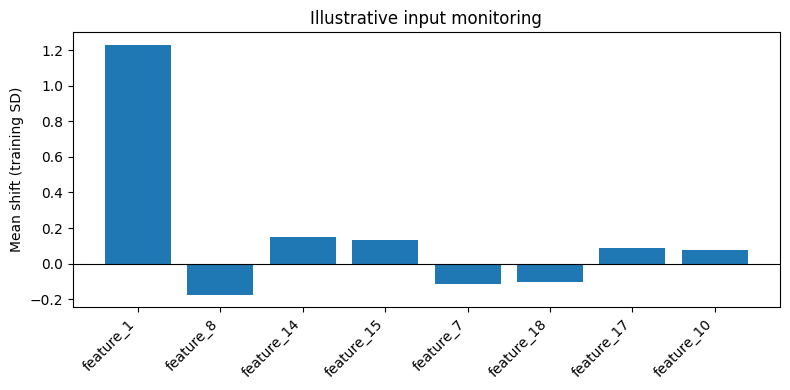

In [4]:

incoming=X_test.copy(); incoming[:,0]+=1.25
mean_train=X_train.mean(axis=0); std_train=X_train.std(axis=0)+1e-8
mean_incoming=incoming.mean(axis=0)
shift=(mean_incoming-mean_train)/std_train
drift=pd.DataFrame({"Feature":[f"feature_{i+1}" for i in range(X.shape[1])],
"Training mean":mean_train,"Incoming mean":mean_incoming,"Shift (training SD)":shift})
drift=drift.sort_values("Shift (training SD)",key=np.abs,ascending=False)
display(drift.head(8).round(3))
plt.figure(figsize=(8,4)); plt.bar(drift.head(8).Feature,drift.head(8)["Shift (training SD)"])
plt.axhline(0,color="black",linewidth=.8); plt.ylabel("Mean shift (training SD)")
plt.title("Illustrative input monitoring"); plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()


Input drift does not automatically mean predictive quality has degraded. When labels arrive, monitor task metrics too; define alert thresholds with domain context and investigate before retraining.

## 5. Record metadata

In [5]:

metadata={"model_name":"logistic_regression_pipeline","artifact_path":str(model_path),
"python_version":platform.python_version(),"scikit_learn_version":sklearn.__version__,
"training_samples":int(len(X_train)),"input_features":int(X_train.shape[1]),
"test_accuracy":float(accuracy_score(y_test,loaded.predict(X_test))),"random_state":RANDOM_STATE}
metadata_path=artifact_dir/"metadata.json"
metadata_path.write_text(json.dumps(metadata,indent=2),encoding="utf-8")
print(metadata_path.read_text())


{
  "model_name": "logistic_regression_pipeline",
  "artifact_path": "model_artifacts/classification_pipeline.joblib",
  "python_version": "3.13.5",
  "scikit_learn_version": "1.8.0",
  "training_samples": 900,
  "input_features": 20,
  "test_accuracy": 0.82,
  "random_state": 42
}


### Production checklist
- Package preprocessing and estimator together; record versions and training metadata.
- Validate input schema, feature order, missing values, and data types.
- Choose batch, API, or scheduled inference based on latency and throughput.
- Monitor errors, latency, input drift, prediction distributions, and quality when labels arrive.
- Compare candidate models with a baseline and retain a rollback option.
- Restrict artifact access and load serialized models only from trusted sources.

## Exercises
1. Compare single-row and batch inference timing.
2. Change the simulated feature shift and propose an alert threshold.
3. Add model version and training timestamp to metadata.
4. Explain why saving a pipeline is useful.
5. Describe how to validate a replacement model.

## Summary
Deployment is more than saving a model: it includes reliable inference, versioning, monitoring, and controlled updates. Pipelines preserve preprocessing consistency and monitoring supports investigation and retraining.